# 🏛️ Topic 3: Hierarchical Agent Teams with RAG
### Enterprise-Grade Multi-Tier Orchestration (Team-of-Teams Architecture)

---

## 📌 Architectural Overview
When an enterprise task grows in complexity or involves many specialized roles, a single supervisor becomes a bottleneck and suffers from context overload. **Hierarchical Agent Teams** solve this by decomposing the system into specialized, autonomous subgraphs (teams), each governed by its own mid-level team supervisor, all reporting to a top-level meta-supervisor.

### System Hierarchy:
1. **🏛️ Top-Level Meta-Supervisor:**
   - Routes work between high-level teams: `['research_team', 'writing_team', 'FINISH']`.
   - Maintains the strategic objective and orchestrates cross-team handoffs.
2. **🔬 Research Team Subgraph:**
   - **Research Supervisor:** Manages intra-team work.
   - **🔎 Search Agent:** Queries internal RAG notes (`InternalResearchNotes`) and live web (`TavilySearch`).
   - **🕷️ Web Scraper Agent:** Fetches full web pages and extracts structured text via `WebBaseLoader` / BeautifulSoup (`scrape_webpages`).
3. **📝 Document Writing Team Subgraph:**
   - **Doc Writing Supervisor:** Coordinates document creation pipeline.
   - **📋 Note Taker Agent:** Plans document outlines (`create_outline`, `read_document`).
   - **✍️ Document Writer Agent:** Drafts, edits, and refines markdown sections (`write_document`, `edit_document`, `read_document`).
   - **📊 Chart Generator Agent:** Executes Python code safely to calculate analytics and generate charts (`python_repl_tool`, `PythonREPL`).

---

### 🎨 Architecture Diagram
![Hierarchical Agent Teams Architecture](images/hierarchical_agent_teams_architecture.png)


### 1. Environment & API Keys Setup
Loads API keys from the root `.env` file, suppresses OpenMP duplicate library warnings on Windows, and prevents HuggingFace hub network checks.

In [1]:
import os
import sys

# Suppress OpenMP runtime conflicts on Windows
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
# Use cached HuggingFace models offline without network stalls
os.environ["HF_HUB_OFFLINE"] = "1"

from dotenv import load_dotenv, find_dotenv

# Load keys from workspace root .env
load_dotenv(find_dotenv(usecwd=True))
sys.path.append(os.path.abspath(".."))

print("🔑 Environment Configuration:")
print("- TAVILY_API_KEY:", "✅ Configured" if os.getenv("TAVILY_API_KEY") else "❌ Missing")
print("- GROQ_API_KEY:  ", "✅ Configured" if os.getenv("GROQ_API_KEY") else "❌ Missing")
print("- OPENAI_API_KEY:", "✅ Configured" if os.getenv("OPENAI_API_KEY") else "❌ Missing")

🔑 Environment Configuration:
- TAVILY_API_KEY: ✅ Configured
- GROQ_API_KEY:   ✅ Configured
- OPENAI_API_KEY: ✅ Configured


### 2. Centralized LLM Initialization
Initializes the chat model using `llm_config.get_llm()` for structured routing and agent tool execution.

In [2]:
from llm_config import get_llm

llm = get_llm(temperature=0.1)
test_res = llm.invoke("Hello! Give a 1-sentence description of hierarchical multi-agent teams.")
print("🤖 LLM Response:", test_res.content.strip())

🤖 LLM Response: Hierarchical multi-agent teams are structured systems where specialized agents are organized into a top-down chain of command, with higher-level agents delegating tasks and coordinating the actions of subordinate agents to achieve complex goals.


### 3. Team State Definition & Supervisor Router Factory
All subgraphs share a common `State` inheriting from `MessagesState`, augmented with a `next` field for routing.
`make_supervisor_node` creates an LLM-based router using structured output (`with_structured_output`) to deterministically decide which worker or team to invoke next.


In [3]:
from typing import List, Optional, Literal, Dict, Annotated
from typing_extensions import TypedDict
from langchain_core.language_models.chat_models import BaseChatModel
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.types import Command
from langchain_core.messages import HumanMessage, BaseMessage

# Shared state across all team levels
class State(MessagesState):
    next: str

def make_supervisor_node(llm: BaseChatModel, members: list[str]):
    """Factory to generate structured routing nodes for supervisors at any hierarchy level."""
    options = ["FINISH"] + members
    system_prompt = (
        "You are a supervisor tasked with managing a conversation between the"
        f" following workers: {members}. Given the current context and user request,"
        " respond with the worker to act next. Each worker will perform their assigned"
        " task and report back with their findings and status. When the objective is fulfilled,"
        " respond with FINISH."
    )

    # Use tuple conversion instead of unpacking with * inside Literal
    RouterType = Literal[tuple(options)]  # type: ignore

    class Router(TypedDict):
        """Worker or team to route to next. If no workers needed, route to FINISH."""
        next: RouterType

    # Construct the Command type parameter using a tuple or str to avoid * syntax errors
    CommandTargetType = Literal[tuple(members + ["__end__"])]  # type: ignore

    def supervisor_node(state: State) -> Command[CommandTargetType]:
        messages = [
            {"role": "system", "content": system_prompt},
        ] + state["messages"]
        response = llm.with_structured_output(Router).invoke(messages)
        goto = response["next"]
        if goto == "FINISH":
            goto = END

        return Command(goto=goto, update={"next": goto})

    return supervisor_node

print("✅ State and make_supervisor_node factory initialized.")

✅ State and make_supervisor_node factory initialized.


### 4. Team 1: Research Team Subgraph
Equips the Research Team with:
1. **`InternalResearchNotes`:** FAISS vector store over `data/research_notes.txt`.
2. **`TavilySearch`:** Fast web search.
3. **`scrape_webpages`:** In-depth webpage content extraction using `WebBaseLoader` / BeautifulSoup.

The team has a mid-level supervisor routing between `search` and `web_scraper`.


In [4]:
from pydantic import BaseModel, Field
from langchain_core.tools import StructuredTool, tool
from langchain_community.document_loaders import TextLoader, WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_tavily import TavilySearch
from langgraph.prebuilt import create_react_agent

# 1. RAG Retriever
class RetrieverQueryInput(BaseModel):
    query: str = Field(description="Search query to retrieve empirical research notes")

def make_retriever_tool_from_text(file_path: str, name: str, desc: str):
    possible_paths = [
        file_path,
        os.path.join("..", file_path),
        os.path.join("..", "data", os.path.basename(file_path)),
        os.path.join("data", os.path.basename(file_path)),
        os.path.join("..", "data", "research_notes.txt"),
        os.path.join("data", "research_notes.txt"),
    ]
    resolved_path = next((p for p in possible_paths if os.path.exists(p)), os.path.join("..", "data", "research_notes.txt"))
    docs = TextLoader(resolved_path, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    emb = HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        model_kwargs={"local_files_only": True}
    )
    vs = FAISS.from_documents(chunks, emb)
    retriever = vs.as_retriever(search_kwargs={"k": 2})

    def tool_func(query: str) -> str:
        print(f"📚 [Research Team RAG] Query: '{query}'")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results[:2])

    return StructuredTool.from_function(
        func=tool_func,
        name=name,
        description=desc,
        args_schema=RetrieverQueryInput
    )

internal_tool_1 = make_retriever_tool_from_text(
    "research_notes.txt",
    "InternalResearchNotes",
    "Search internal research notes for experimental results, model evaluations, accuracy metrics, and benchmark data."
)
tavily_tool = TavilySearch(max_results=3)

# 2. Web Scraping Tool
@tool
def scrape_webpages(urls: List[str]) -> str:
    """Use requests and bs4 to scrape the provided web pages for detailed information."""
    try:
        loader = WebBaseLoader(urls)
        docs = loader.load()
        return "\n\n".join(
            [f'<Document name="{doc.metadata.get("title", "")}">\n{doc.page_content[:1500]}\n</Document>' for doc in docs]
        )
    except Exception as e:
        return f"Error scraping URLs: {e}"

# 3. Research Team Agents
search_agent = create_react_agent(
    llm,
    tools=[tavily_tool, internal_tool_1],
    prompt="You are a research search agent. Find facts using the tools and summarize your findings concisely."
)

def search_node(state: State) -> Command[Literal["supervisor"]]:
    result = search_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="search")]},
        goto="supervisor",
    )

web_scraper_agent = create_react_agent(
    llm,
    tools=[scrape_webpages],
    prompt="You are a web scraper agent. Scrape webpage content from given URLs."
)

def web_scraper_node(state: State) -> Command[Literal["supervisor"]]:
    result = web_scraper_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="web_scraper")]},
        goto="supervisor",
    )

# 4. Assemble Research Team Subgraph
research_supervisor_node = make_supervisor_node(llm, ["search", "web_scraper"])

research_builder = StateGraph(State)
research_builder.add_node("supervisor", research_supervisor_node)
research_builder.add_node("search", search_node)
research_builder.add_node("web_scraper", web_scraper_node)
research_builder.add_edge(START, "supervisor")

research_graph = research_builder.compile()
print("✅ Research Team Subgraph compiled successfully!")

C:\Users\itsar\AppData\Local\Temp\ipykernel_11548\3600828175.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader, WebBaseLoader
c:\RAG\Code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
USER_AGENT environment variable not set, consider setting it to identify your requests.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9193.92it/s]


✅ Research Team Subgraph compiled successfully!


C:\Users\itsar\AppData\Local\Temp\ipykernel_11548\3600828175.py:66: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  search_agent = create_react_agent(
C:\Users\itsar\AppData\Local\Temp\ipykernel_11548\3600828175.py:79: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  web_scraper_agent = create_react_agent(


### 5. Team 2: Document Writing Team Subgraph
The Writing Team operates within a shared virtual workspace (directory) to draft, edit, and enrich documents:
1. **`create_outline`:** Note Taker creates structured headings and bullet outlines.
2. **`write_document` / `edit_document`:** Document Writer creates and iteratively edits sections.
3. **`read_document`:** Reads documents from the virtual filesystem.
4. **`python_repl_tool`:** Chart Generator runs Python scripts to compute data tables or generate charts.

The team has a mid-level supervisor routing between `note_taker`, `doc_writer`, and `chart_generator`.


In [5]:
from pathlib import Path
from tempfile import TemporaryDirectory
from langchain_experimental.utilities import PythonREPL

_TEMP_DIRECTORY = TemporaryDirectory()
WORKING_DIRECTORY = Path(_TEMP_DIRECTORY.name)

# 1. Document Management Tools
@tool
def create_outline(
    points: Annotated[List[str], "List of main points or sections."],
    file_name: Annotated[str, "File path to save the outline."],
) -> Annotated[str, "Path of the saved outline file."]:
    """Create and save a document outline."""
    with (WORKING_DIRECTORY / file_name).open("w", encoding="utf-8") as file:
        for i, point in enumerate(points):
            file.write(f"{i + 1}. {point}\n")
    return f"Outline successfully saved to {file_name}"

@tool
def read_document(
    file_name: Annotated[str, "File path to read the document from."],
    start: Annotated[Optional[int], "The start line (0-indexed). Default is 0"] = None,
    end: Annotated[Optional[int], "The end line. Default is None"] = None,
) -> str:
    """Read the specified document."""
    doc_path = WORKING_DIRECTORY / file_name
    if not doc_path.exists():
        return f"File {file_name} does not exist yet."
    with doc_path.open("r", encoding="utf-8") as file:
        lines = file.readlines()
    start_idx = start if start is not None else 0
    return "".join(lines[start_idx:end])

@tool
def write_document(
    content: Annotated[str, "Text content to be written into the document."],
    file_name: Annotated[str, "File path to save the document."],
) -> Annotated[str, "Path of the saved document file."]:
    """Create and save a text document."""
    with (WORKING_DIRECTORY / file_name).open("w", encoding="utf-8") as file:
        file.write(content)
    return f"Document successfully written to {file_name}"

@tool
def edit_document(
    file_name: Annotated[str, "Path of the document to be edited."],
    inserts: Annotated[Dict[int, str], "Dictionary where key is 1-indexed line number and value is text to insert."],
) -> Annotated[str, "Path of the edited document file."]:
    """Edit a document by inserting text at specific line numbers."""
    doc_path = WORKING_DIRECTORY / file_name
    if not doc_path.exists():
        return f"File {file_name} does not exist."
    with doc_path.open("r", encoding="utf-8") as file:
        lines = file.readlines()

    for line_number, text in sorted(inserts.items()):
        if 1 <= line_number <= len(lines) + 1:
            lines.insert(line_number - 1, text + "\n")
        else:
            return f"Error: Line number {line_number} is out of range."

    with doc_path.open("w", encoding="utf-8") as file:
        file.writelines(lines)
    return f"Document successfully edited and saved to {file_name}"

# 2. Python REPL Tool for Chart Generator
repl = PythonREPL()

@tool
def python_repl_tool(code: Annotated[str, "The python code to execute."]) -> str:
    """Execute python code for calculations and analytics."""
    try:
        result = repl.run(code)
    except Exception as e:
        return f"Failed to execute. Error: {e}"
    return f"Execution stdout:\n{result}"

# 3. Writing Team Agents
note_taking_agent = create_react_agent(
    llm,
    tools=[create_outline, read_document],
    prompt="You are a note-taking agent. Read research dossiers and create detailed document outlines."
)

def note_taking_node(state: State) -> Command[Literal["supervisor"]]:
    result = note_taking_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="note_taker")]},
        goto="supervisor",
    )

doc_writer_agent = create_react_agent(
    llm,
    tools=[write_document, edit_document, read_document],
    prompt="You are a document writing agent. Write and edit comprehensive sections based on outlines."
)

def doc_writing_node(state: State) -> Command[Literal["supervisor"]]:
    result = doc_writer_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="doc_writer")]},
        goto="supervisor",
    )

chart_generating_agent = create_react_agent(
    llm,
    tools=[read_document, python_repl_tool],
    prompt="You are a data analytics and chart agent. Execute python code to verify metrics and generate statistics."
)

def chart_generating_node(state: State) -> Command[Literal["supervisor"]]:
    result = chart_generating_agent.invoke(state)
    return Command(
        update={"messages": [HumanMessage(content=result["messages"][-1].content, name="chart_generator")]},
        goto="supervisor",
    )

# 4. Assemble Writing Team Subgraph
doc_writing_supervisor_node = make_supervisor_node(llm, ["note_taker", "doc_writer", "chart_generator"])

paper_writing_builder = StateGraph(State)
paper_writing_builder.add_node("supervisor", doc_writing_supervisor_node)
paper_writing_builder.add_node("note_taker", note_taking_node)
paper_writing_builder.add_node("doc_writer", doc_writing_node)
paper_writing_builder.add_node("chart_generator", chart_generating_node)
paper_writing_builder.add_edge(START, "supervisor")

paper_writing_graph = paper_writing_builder.compile()
print("✅ Document Writing Team Subgraph compiled successfully!")

✅ Document Writing Team Subgraph compiled successfully!


C:\Users\itsar\AppData\Local\Temp\ipykernel_11548\3581100819.py:3: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.utilities import PythonREPL
C:\Users\itsar\AppData\Local\Temp\ipykernel_11548\3581100819.py:80: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  note_taking_agent = create_react_agent(
C:\Users\itsar\AppData\Local\Temp\ipykernel_11548\3581100819.py:93: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  doc_writer_agent = create_react_agent(
C:\Users\itsar\AppData\Local\Temp\ipykernel_11548\3

### 6. Top-Level Meta-Supervisor & Super Graph Assembly
We define the top-level orchestration:
- `call_research_team`: Delegates the query to the `research_graph` subgraph, extracts the team's final conclusion, and reports back.
- `call_paper_writing_team`: Delegates the findings to the `paper_writing_graph` subgraph, extracts the written deliverable, and reports back.
- `teams_supervisor_node`: High-level router choosing between `research_team` and `writing_team`.


In [6]:
# 1. Team Delegation Nodes
def call_research_team(state: State) -> Command[Literal["supervisor"]]:
    """Delegates query to the Research Team subgraph."""
    response = research_graph.invoke({"messages": state["messages"][-1:]})
    return Command(
        update={"messages": [HumanMessage(content=response["messages"][-1].content, name="research_team")]},
        goto="supervisor",
    )

def call_paper_writing_team(state: State) -> Command[Literal["supervisor"]]:
    """Delegates findings to the Document Writing Team subgraph."""
    response = paper_writing_graph.invoke({"messages": state["messages"][-1:]})
    return Command(
        update={"messages": [HumanMessage(content=response["messages"][-1].content, name="writing_team")]},
        goto="supervisor",
    )

# 2. Meta-Supervisor
teams_supervisor_node = make_supervisor_node(llm, ["research_team", "writing_team"])

# 3. Assemble Super Graph
super_builder = StateGraph(State)
super_builder.add_node("supervisor", teams_supervisor_node)
super_builder.add_node("research_team", call_research_team)
super_builder.add_node("writing_team", call_paper_writing_team)
super_builder.add_edge(START, "supervisor")

super_graph = super_builder.compile()
print("✅ Top-Level Super Graph compiled successfully!")

✅ Top-Level Super Graph compiled successfully!


### 7. Visualizing the Hierarchical Graphs
We render:
1. **Top-Level Super Graph:** Showing orchestration between the meta-supervisor and teams.
2. **Research Team Subgraph:** Internal worker topology.
3. **Writing Team Subgraph:** Internal document worker topology.


📊 1. Top-Level Super Graph:


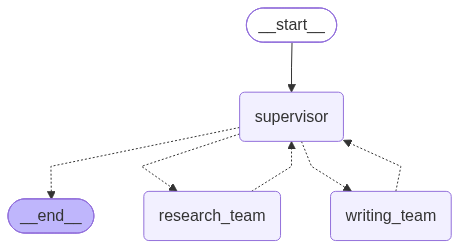


📊 2. Research Team Subgraph:


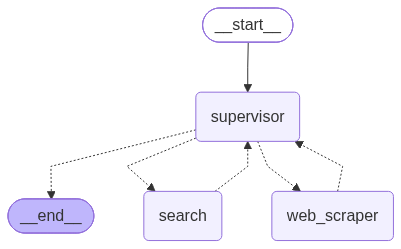


📊 3. Document Writing Team Subgraph:


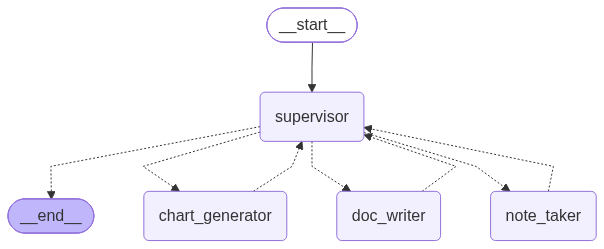

In [7]:
from IPython.display import Image, display

print("📊 1. Top-Level Super Graph:")
try:
    png_super = super_graph.get_graph().draw_mermaid_png()
    display(Image(png_super))
except Exception as e:
    print("Render note:", e)

print("\n📊 2. Research Team Subgraph:")
try:
    png_res = research_graph.get_graph().draw_mermaid_png()
    display(Image(png_res))
except Exception as e:
    print("Render note:", e)

print("\n📊 3. Document Writing Team Subgraph:")
try:
    png_doc = paper_writing_graph.get_graph().draw_mermaid_png()
    display(Image(png_doc))
except Exception as e:
    print("Render note:", e)

### 8. End-to-End Execution of Hierarchical Teams
We trigger an enterprise request:
> *"Research transformer variants evaluated in production deployments from internal notes and draft a structured technical overview with key performance metrics."*


In [ ]:
task_query = (
    "Research transformer variants evaluated in production deployments from our internal notes, "
    "and create a structured technical overview detailing accuracy, memory usage, and latency."
)
print(f"🚀 Invoking Hierarchical Agent Super-Graph with Task:\n'{task_query}'\n" + "="*70)

response = super_graph.invoke({
    "messages": [HumanMessage(content=task_query)]
})

print(f"\n🎯 Execution completed! Total team exchanges: {len(response['messages'])}\n")
print("="*70 + "\n🏁 FINAL DELIVERABLE FROM TEAMS:\n" + "="*70)
print(response["messages"][-1].content)

🚀 Invoking Hierarchical Agent Super-Graph with Task:
'Research transformer variants evaluated in production deployments from our internal notes, and create a structured technical overview detailing accuracy, memory usage, and latency.'
📚 [Research Team RAG] Query: 'transformer variants production deployment accuracy memory latency'
📚 [Research Team RAG] Query: 'production model evaluation benchmark results'
📚 [Research Team RAG] Query: 'Reformer production deployment results accuracy'
📚 [Research Team RAG] Query: 'EfficientFormer Longformer LLaMA2 memory usage latency comparison'


### 9. High-Level Team Trajectory Inspection
Examines the inter-team communication between the Meta-Supervisor, the Research Team, and the Writing Team.

In [ ]:
print("📜 Inter-Team Execution Log:")
for i, msg in enumerate(response["messages"]):
    name = getattr(msg, "name", "user") or msg.type
    content = str(msg.content)[:160].replace("\n", " ")
    print(f"[{i:02d}] {name.upper():<20} : {content}...")

### 10. Enterprise Architectural Best Practices

| Best Practice | Implementation in Hierarchical Teams |
| :--- | :--- |
| **Cognitive Load Reduction** | Individual worker agents only maintain intra-team context; meta-supervisor only sees team summaries. |
| **Independent Testability** | Subgraphs (`research_graph`, `paper_writing_graph`) can be unit-tested and benchmarked independently before being plugged into the super-graph. |
| **Shared Working Memory** | Long documents, outlines, and artifacts live in a shared workspace filesystem (`WORKING_DIRECTORY`), avoiding huge context window costs. |
| **Security & Sandboxing** | Tools with code execution capabilities (`python_repl_tool`) are isolated within specialized agents and sandbox environments. |
| **Team Scaling** | New specialized teams (e.g., `qa_team`, `translation_team`, `compliance_team`) can be plugged into the meta-supervisor with zero changes to existing teams. |
